<a href="https://colab.research.google.com/github/Haikal5-prog/titanic-survival-prediction/blob/main/titanic_survival_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df=sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df.shape #891 penumpang(row) dan 15 column

(891, 15)

In [4]:
#untuk kenal data (EDA)
df.info() #tahu info table punya non-null brp dan datatype
df.isnull().sum() #tahu jumlah yang nilainya kosong dalam table

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


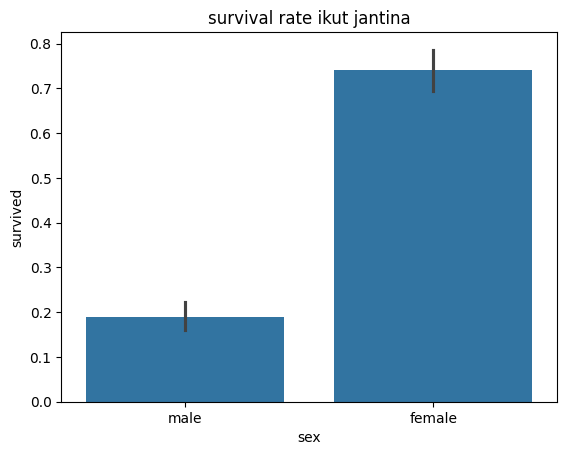

In [6]:
#buat graf utk tahu kaitan jantina dan rate survival
sns.barplot(x="sex", y="survived", data=df)
plt.title("survival rate ikut jantina")
plt.show()

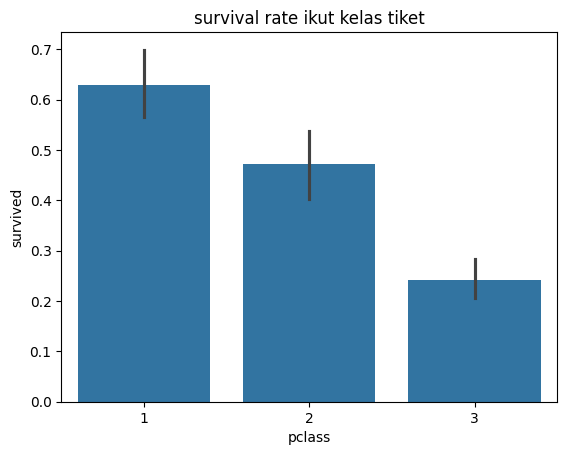

In [7]:
#nak tahun hubungan kelas tiket dgn survival rate
sns.barplot(x="pclass", y="survived", data=df)
plt.title("survival rate ikut kelas tiket")
plt.show()

In [9]:
#pilih kolum yang kita nk guna je
df=df[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]]

#isi age yang kosong dgn median
df["age"]=df["age"].fillna(df["age"].median())

#buang baris yang embarked kosong, tkpe sbb 2 je yg kosong
df= df.dropna(subset=["embarked"])

#tukar teks jadi nombor sbb model faham nombor je
df=pd.get_dummies(df, columns=["sex", "embarked"], drop_first=True)

df.head()

,survived,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,35.0,0,0,8.0500,True,False,True


In [12]:
#semak data sekali lagi, nk tentukan betul ii clean
df.shape
df.isnull().sum()

,0
survived,0
pclass,0
age,0
sibsp,0
parch,0
fare,0
sex_male,0
embarked_Q,0
embarked_S,0


In [13]:
df.shape

(889, 9)

In [14]:
from sklearn.model_selection import train_test_split

X = df.drop("survived", axis=1)
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)


(711, 8) (178, 8)


In [16]:
#train model yang pertama guna logistic regression

from sklearn.linear_model import LogisticRegression

lr=LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [17]:
#cara nk tgok weight yang diletak keatas setiap value dalam model linear Regression
pd.Series(lr.coef_[0], index=X_train.columns).sort_values()

,0
sex_male,-2.545921
pclass,-1.014576
embarked_S,-0.311683
sibsp,-0.237344
parch,-0.092819
age,-0.035536
fare,0.002660
embarked_Q,0.319120


In [18]:
#Trainin model yang kedua pakai Random Forest
from sklearn.ensemble import RandomForestClassifier

rf=RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [19]:
#nak tgok random forest
print(len(rf.estimators_)) #100 pokok
print(rf.estimators_[0].get_depth()) #kedalaman pokok pertama

100
18


In [20]:
print(lr)
print(rf)

LogisticRegression(max_iter=1000)
RandomForestClassifier(random_state=42)


In [21]:
#skrang nk uji model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

for name, model in [("Logistic Regression", lr), ("Random Forest", rf)]:
    pred = model.predict(X_test)
    print(name)
    print("Accuracy:", accuracy_score(y_test, pred))
    print(classification_report(y_test, pred))
    print(confusion_matrix(y_test, pred))
    print("-" * 40)

Logistic Regression
Accuracy: 0.8146067415730337
              precision    recall  f1-score   support

           0       0.82      0.89      0.86       110
           1       0.80      0.69      0.74        68

    accuracy                           0.81       178
   macro avg       0.81      0.79      0.80       178
weighted avg       0.81      0.81      0.81       178

[[98 12]
 [21 47]]
----------------------------------------
Random Forest
Accuracy: 0.797752808988764
              precision    recall  f1-score   support

           0       0.82      0.86      0.84       110
           1       0.76      0.69      0.72        68

    accuracy                           0.80       178
   macro avg       0.79      0.78      0.78       178
weighted avg       0.80      0.80      0.80       178

[[95 15]
 [21 47]]
----------------------------------------


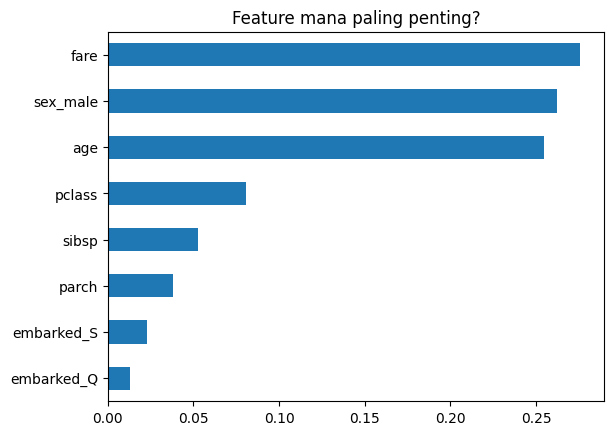

In [23]:
#Feature importance, nak tahu feature mana yang lebih berpengaruh keatas Random Forest
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importances.plot(kind="barh", title="Feature mana paling penting?")
plt.show()